# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Rakha Makarim | 5054251010 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan:
# pandas, numpy, matplotlib, seaborn
# StandardScaler dari sklearn.preprocessing
# DBSCAN dari sklearn.cluster
# Birch dari sklearn.cluster
# GaussianMixture dari sklearn.mixture
# silhouette_score, davies_bouldin_score, calinski_harabasz_score dari sklearn.metrics

%matplotlib inline

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42


In [2]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
# Jika file tidak ditemukan, periksa lokasi file dan nama file.
# Tampilkan 5 baris pertama, jumlah baris/kolom, tipe data, statistik deskriptif,
# jumlah missing value, dan jumlah baris duplikat.

candidates = [
    Path("../Data/Mall_Customers.csv"),
    Path("Data/Mall_Customers.csv"),
    Path("DBSCAN, BIRCH, EM/Data/Mall_Customers.csv"),
]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Mall_Customers.csv tidak ditemukan; periksa lokasi file.")

df = pd.read_csv(DATA_PATH)

print("File:", DATA_PATH.resolve())
print("\n5 baris pertama:")
print(df.head().to_string(index=False))
print("\nJumlah baris, kolom:", df.shape)
print("\nTipe data:")
print(df.dtypes.to_string())
print("\nStatistik deskriptif:")
print(df.describe().T.to_string())
print("\nJumlah missing value per kolom:")
print(df.isna().sum().to_string())
print("\nJumlah missing value total:", int(df.isna().sum().sum()))
print("Jumlah baris duplikat (semua kolom):", int(df.duplicated().sum()))
print("Jumlah baris duplikat (tanpa CustomerID):",
      int(df.drop(columns=["CustomerID"]).duplicated().sum()))


File: /home/makarim/Desktop/Collage/Machine Learning/Task_ML/DBSCAN, BIRCH, EM/Data/Mall_Customers.csv

5 baris pertama:
 CustomerID Gender  Age  Annual Income (k$)  Spending Score (1-100)
          1   Male   19                  15                      39
          2   Male   21                  15                      81
          3 Female   20                  16                       6
          4 Female   23                  16                      77
          5 Female   31                  17                      40

Jumlah baris, kolom: (200, 5)

Tipe data:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64

Statistik deskriptif:
                        count    mean        std   min    25%    50%     75%    max
CustomerID              200.0  100.50  57.879185   1.0  50.75  100.5  150.25  200.0
Age                     200.0   38.85  13.969007  18.0  28.75   36.0   49.00 

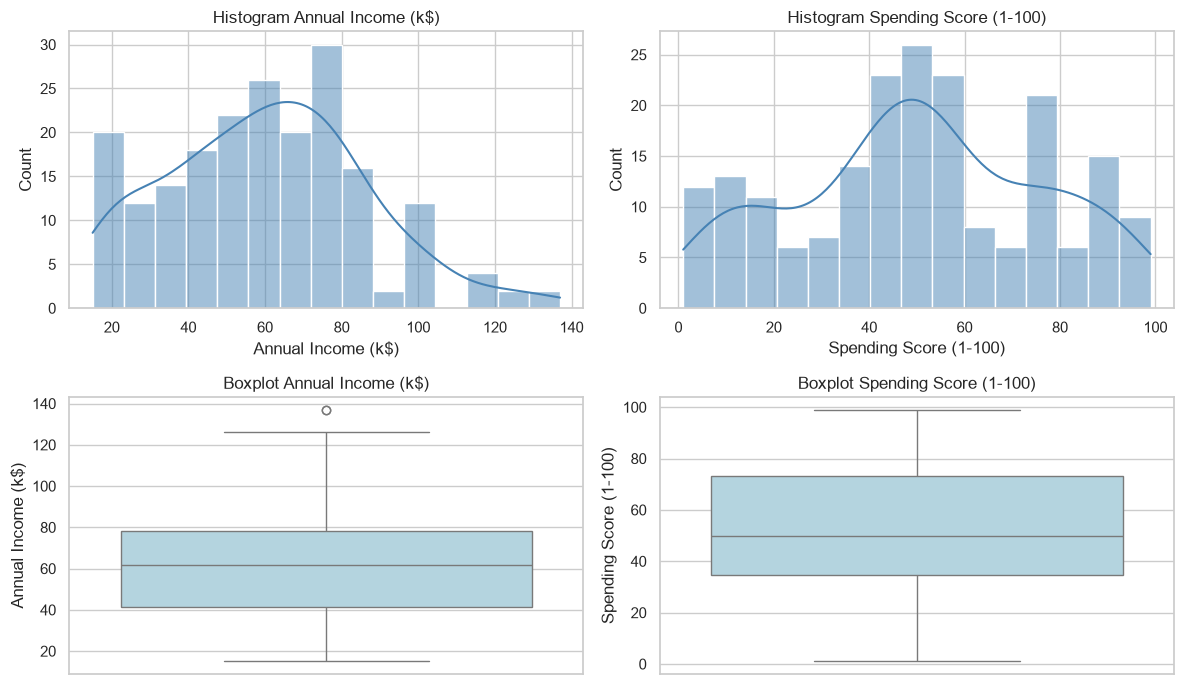

Ringkasan dua fitur utama:
        Annual Income (k$)  Spending Score (1-100)
min                   15.0                     1.0
median                61.5                    50.0
max                  137.0                    99.0
mean                  60.6                    50.2


In [3]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan/atau boxplot.
# Amati rentang, bentuk distribusi, dan kemungkinan outlier.

feats = ["Annual Income (k$)", "Spending Score (1-100)"]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for j, f in enumerate(feats):
    sns.histplot(data=df, x=f, bins=15, kde=True, ax=axes[0, j], color="steelblue")
    axes[0, j].set_title(f"Histogram {f}")
    sns.boxplot(y=df[f], ax=axes[1, j], color="lightblue")
    axes[1, j].set_title(f"Boxplot {f}")
plt.tight_layout()
plt.show()

print("Ringkasan dua fitur utama:")
print(df[feats].agg(["min", "median", "max", "mean"]).round(1).to_string())


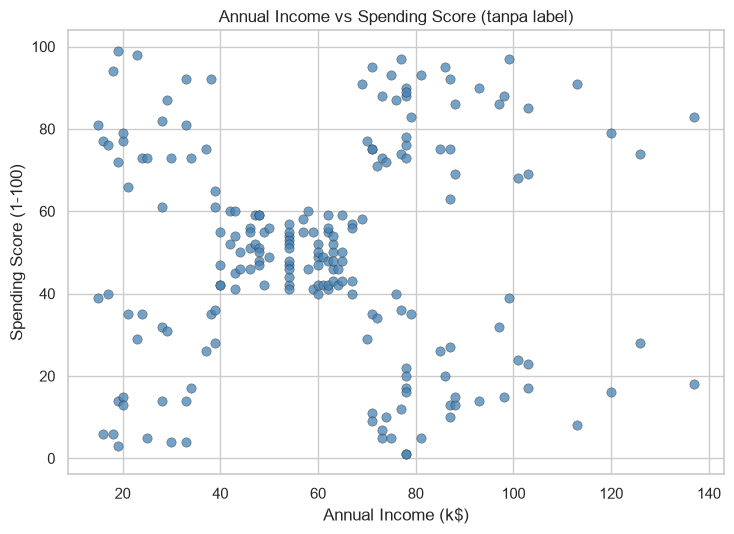

In [4]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
# Jangan warnai berdasarkan label apa pun terlebih dahulu.
# Amati apakah terlihat kelompok-kelompok yang terpisah.

plt.figure(figsize=(7.5, 5.5))
plt.scatter(df[feats[0]], df[feats[1]], s=45, alpha=0.75, color="steelblue",
            edgecolor="k", linewidth=0.3)
plt.xlabel(feats[0])
plt.ylabel(feats[1])
plt.title("Annual Income vs Spending Score (tanpa label)")
plt.tight_layout()
plt.show()


## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?
**Jawaban:**

- **Missing value / duplikat:** Tidak ada. Seluruh 200 baris lengkap (0 missing value) dan tidak ada baris duplikat, bahkan setelah kolom `CustomerID` diabaikan.
- **Rentang:** `Annual Income (k$)` berkisar 15–137 (median 61,5; mean 60,6) dan `Spending Score (1-100)` berkisar 1–99 (median 50,0). Pendapatan sedikit condong ke kanan (*right-skewed*) dengan sejumlah outlier pendapatan tinggi (≥100 k$), sedangkan spending score terdistribusi cukup merata di seluruh rentang.
- **Kelompok terpisah:** Ya. Scatter plot tanpa warna sudah memperlihatkan sekitar lima gugusan yang cukup jelas — dua gugusan di sisi kiri (pendapatan rendah, spending rendah dan tinggi), dua di sisi kanan (pendapatan tinggi, spending rendah dan tinggi), serta satu gugusan besar di tengah.


# 2. Preprocessing

In [5]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik:
#   Annual Income (k$)
#   Spending Score (1-100)
# Simpan dalam DataFrame X.

print("Missing value total:", int(df.isna().sum().sum()))
print("Duplikat (tanpa CustomerID):", int(df.drop(columns=["CustomerID"]).duplicated().sum()))
# Data bersih (tanpa missing/duplikat), jadi tidak perlu imputasi atau penghapusan baris.

# CustomerID hanya identitas, Gender tidak dipakai pada eksperimen utama.
X = df[["Annual Income (k$)", "Spending Score (1-100)"]].copy()

print("\nFitur clustering:", list(X.columns))
print("Bentuk X:", X.shape)
print(X.head().to_string(index=False))


Missing value total: 0
Duplikat (tanpa CustomerID): 0

Fitur clustering: ['Annual Income (k$)', 'Spending Score (1-100)']
Bentuk X: (200, 2)
 Annual Income (k$)  Spending Score (1-100)
                 15                      39
                 15                      81
                 16                       6
                 16                      77
                 17                      40


In [6]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
# Tampilkan beberapa baris X_scaled dan statistik deskriptifnya.

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

print("Beberapa baris X_scaled:")
print(X_scaled.head().to_string(index=False))
print("\nStatistik deskriptif X_scaled:")
print(X_scaled.describe().T[["mean", "std", "min", "max"]].round(3).to_string())


Beberapa baris X_scaled:
 Annual Income (k$)  Spending Score (1-100)
          -1.738999               -0.434801
          -1.738999                1.195704
          -1.700830               -1.715913
          -1.700830                1.040418
          -1.662660               -0.395980

Statistik deskriptif X_scaled:
                        mean    std    min    max
Annual Income (k$)      -0.0  1.003 -1.739  2.918
Spending Score (1-100)  -0.0  1.003 -1.910  1.894


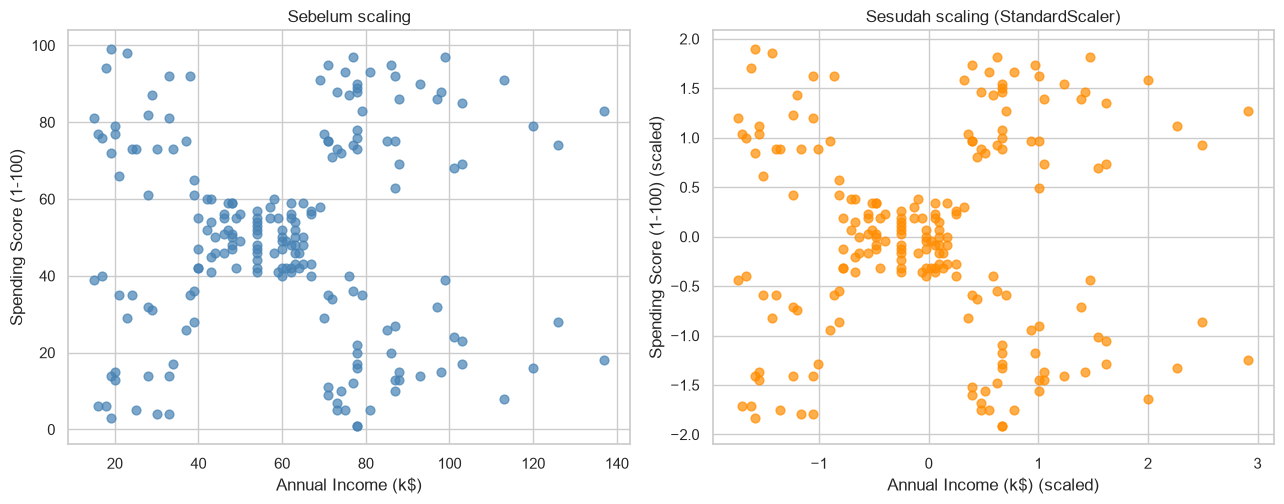

Rentang sebelum: {'Annual Income (k$)': (15, 137), 'Spending Score (1-100)': (1, 99)}
Rentang sesudah: {'Annual Income (k$)': (np.float64(-1.74), np.float64(2.92)), 'Spending Score (1-100)': (np.float64(-1.91), np.float64(1.89))}

Mengapa scaling penting:
- DBSCAN menentukan tetangga dari jarak Euclidean terhadap eps. Tanpa scaling,
  rentang Annual Income (15-137) lebih lebar daripada Spending Score (1-99),
  sehingga jarak hampir sepenuhnya ditentukan oleh pendapatan.
- BIRCH mengelompokkan titik dalam radius threshold dan GMM memodelkan sebaran
  tiap dimensi; keduanya mengasumsikan sumbu fitur sebanding, agar tidak ada
  fitur yang mendominasi bentuk cluster.



In [7]:
# Buat scatter plot sebelum dan sesudah scaling.
# Jelaskan mengapa scaling penting, terutama ketika algoritma menggunakan jarak
# atau mengasumsikan skala fitur yang sebanding.

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
axes[0].scatter(X[feats[0]], X[feats[1]], s=40, alpha=0.7, color="steelblue")
axes[0].set_title("Sebelum scaling")
axes[0].set_xlabel(feats[0])
axes[0].set_ylabel(feats[1])
axes[1].scatter(X_scaled[feats[0]], X_scaled[feats[1]], s=40, alpha=0.7, color="darkorange")
axes[1].set_title("Sesudah scaling (StandardScaler)")
axes[1].set_xlabel(feats[0] + " (scaled)")
axes[1].set_ylabel(feats[1] + " (scaled)")
plt.tight_layout()
plt.show()

print("Rentang sebelum:", {c: (round(X[c].min()), round(X[c].max())) for c in X.columns})
print("Rentang sesudah:", {c: (round(X_scaled[c].min(), 2), round(X_scaled[c].max(), 2))
                          for c in X_scaled.columns})
print("""
Mengapa scaling penting:
- DBSCAN menentukan tetangga dari jarak Euclidean terhadap eps. Tanpa scaling,
  rentang Annual Income (15-137) lebih lebar daripada Spending Score (1-99),
  sehingga jarak hampir sepenuhnya ditentukan oleh pendapatan.
- BIRCH mengelompokkan titik dalam radius threshold dan GMM memodelkan sebaran
  tiap dimensi; keduanya mengasumsikan sumbu fitur sebanding, agar tidak ada
  fitur yang mendominasi bentuk cluster.
""")


**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.
**Alasan pemilihan fitur:**

- Kedua fitur persis sesuai deskripsi tugas, bertipe numerik, dan mewakili dua sisi ekonomi pelanggan: kemampuan belanja (`Annual Income`) serta perilaku belanja (`Spending Score`) — kombinasi yang lazim untuk segmentasi pelanggan pusat perbelanjaan.
- Hanya dua fitur sehingga hasil clustering mudah divisualisasikan pada scatter plot 2D dan dianalisis per cluster-nya.
- `CustomerID` tidak digunakan karena hanya identitas unik (1–200) tanpa makna jarak; memasukkannya justru menambah dimensi acak sehingga dua pelanggan yang serupa bisa tampak berjauhan. `Gender` bersifat kategorikal dan sengaja dikecualikan dari input model (hanya boleh untuk interpretasi tambahan setelah model selesai, sesuai ketentuan tugas).


# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [8]:
# Jalankan DBSCAN pada X_scaled.
# Mulai dengan eps dan min_samples yang masuk akal, misalnya eps=0.3 dan min_samples=5.
# Simpan label hasil clustering sebagai labels_dbscan.
# Catatan: nilai eps perlu dicoba dan dievaluasi, bukan dianggap pasti paling baik.

dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

print("DBSCAN(eps=0.3, min_samples=5) selesai.")
print("Label unik:", sorted(set(labels_dbscan)))


DBSCAN(eps=0.3, min_samples=5) selesai.
Label unik: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


In [9]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).

vc = pd.Series(labels_dbscan).value_counts().sort_index()
print("Jumlah anggota setiap label:")
print(vc.to_string())

n_clusters = len(set(labels_dbscan) - {-1})
n_noise = int((labels_dbscan == -1).sum())
print("\nJumlah cluster (tanpa label -1):", n_clusters)
print("Jumlah titik noise (label -1) :", n_noise,
      f"({100 * n_noise / len(labels_dbscan):.1f}% data)")


Jumlah anggota setiap label:
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9

Jumlah cluster (tanpa label -1): 7
Jumlah titik noise (label -1) : 35 (17.5% data)


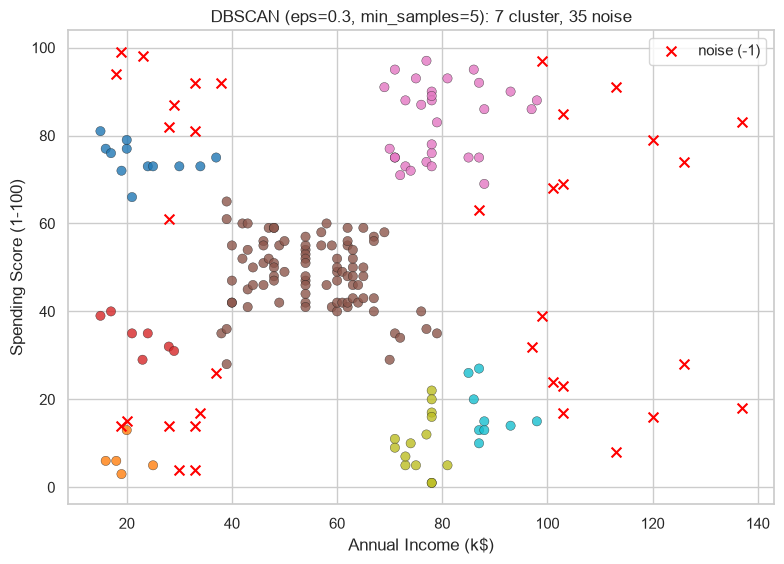

In [10]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan.
# Gunakan X_scaled atau X untuk koordinat plot; untuk interpretasi, X (fitur asli)
# biasanya lebih mudah dipahami.
# Beri judul dan label sumbu yang jelas, serta pastikan noise dapat dibedakan.

xi, yi = X[feats[0]].values, X[feats[1]].values
noise = labels_dbscan == -1

plt.figure(figsize=(8, 5.8))
plt.scatter(xi[~noise], yi[~noise], c=labels_dbscan[~noise], cmap="tab10",
            s=45, alpha=0.8, edgecolor="k", linewidth=0.3)
plt.scatter(xi[noise], yi[noise], c="red", marker="x", s=50, label="noise (-1)")
plt.xlabel(feats[0])
plt.ylabel(feats[1])
plt.title(f"DBSCAN (eps=0.3, min_samples=5): {n_clusters} cluster, {n_noise} noise")
plt.legend()
plt.tight_layout()
plt.show()


In [11]:
# Coba beberapa kombinasi eps dan min_samples.
# Buat tabel ringkasan yang berisi eps, min_samples, jumlah cluster (tanpa noise),
# jumlah noise, dan Silhouette Score jika metrik tersebut valid.
# Hindari menghitung silhouette jika hasilnya hanya satu cluster atau semua titik noise.

eps_list = [0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.6]
ms_list = [3, 5, 8, 10]

rows = []
for eps in eps_list:
    for ms in ms_list:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_cl = len(set(lab) - {-1})
        noise = int((lab == -1).sum())
        non_noise = int((lab != -1).sum())
        sil = None
        if 2 <= n_cl and n_cl < non_noise:  # silhouette hanya valid jika >= 2 cluster
            sil = round(silhouette_score(X_scaled[lab != -1], lab[lab != -1]), 4)
        rows.append({"eps": eps, "min_samples": ms, "n_clusters": n_cl,
                     "noise": noise, "silhouette": sil})
grid_dbscan = pd.DataFrame(rows)
print(grid_dbscan.to_string(index=False))

# Pilihan kombinasi terbaik: minimal 3 cluster, noise <= 30% data, silhouette tertinggi.
kandidat = grid_dbscan[(grid_dbscan["n_clusters"] >= 3) &
                       (grid_dbscan["noise"] <= 0.30 * len(X)) &
                       grid_dbscan["silhouette"].notna()]
best = kandidat.loc[kandidat["silhouette"].idxmax()]
print("\nKombinasi terbaik: eps =", best["eps"],
      "| min_samples =", int(best["min_samples"]),
      "| silhouette =", best["silhouette"],
      "| n_clusters =", int(best["n_clusters"]),
      "| noise =", int(best["noise"]))
labels_dbscan_best = DBSCAN(eps=float(best["eps"]), min_samples=int(best["min_samples"])
                            ).fit_predict(X_scaled)


 eps  min_samples  n_clusters  noise  silhouette
0.20            3          13     44      0.4697
0.20            5           7     77      0.5856
0.20            8           2    116      0.6027
0.20           10           1    129         NaN
0.25            3          12     16      0.4090
0.25            5           6     50      0.5317
0.25            8           5     79      0.5947
0.25           10           2    111      0.7287
0.30            3           9     14      0.4720
0.30            5           7     35      0.5243
0.30            8           5     72      0.5926
0.30           10           4     88      0.6073
0.35            3           7     11      0.5154
0.35            5           6     23      0.5577
0.35            8           4     55      0.5994
0.35           10           5     73      0.5288
0.40            3           4     10      0.3954
0.40            5           4     15      0.4781
0.40            8           5     25      0.5490
0.40           10   

### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?
**Jawaban:**

- **Pengaruh kenaikan `eps`:** Semakin besar `eps`, semakin banyak titik yang dianggap tetangga sehingga cluster saling menyatu dan titik noise terserap kembali. Pada `min_samples=5`, jumlah cluster turun dari 7 (eps=0.2) → 6 (eps=0.35) → 4 (eps=0.4) → 2 (eps=0.5) → 1 (eps=0.6), sementara noise anjlok dari 77 → 23 → 15 → 8 → 5. Ketika eps terlalu besar (0.6), seluruh data melebur menjadi **satu cluster besar** sehingga silhouette tidak lagi valid.
- **Pengaruh `min_samples`:** Semakin besar `min_samples`, syarat menjadi *core point* makin ketat → cluster lebih sedikit dan noise lebih banyak. Pada eps=0.3: min_samples=3 → 9 cluster/14 noise; =5 → 7/35; =8 → 5/72; =10 → 4/88.
- **Kombinasi ekstrem:** (eps besar, min_samples kecil) menghasilkan satu cluster raksasa — eps=0.6, min_samples=3 → 1 cluster, 0 noise. (eps kecil, min_samples besar) membuat noise mendominasi — eps=0.2, min_samples=10 → hanya 1 cluster dengan 129 titik noise. Berdasarkan aturan pemilihan pada cell sebelumnya, kombinasi terbaik adalah **eps=0.35, min_samples=8**: 4 cluster, 55 noise, silhouette 0.5994.


# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [12]:
# Latih model Birch pada X_scaled.
# Coba threshold awal, misalnya 0.5, dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
# Catatan: jumlah cluster akhir dapat berubah sesuai parameter yang digunakan.

birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)

print("Birch(threshold=0.5, n_clusters=5) selesai.")
print("Label unik:", sorted(set(labels_birch)))


Birch(threshold=0.5, n_clusters=5) selesai.
Label unik: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [13]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
# Tampilkan juga jumlah cluster yang terbentuk.

vc = pd.Series(labels_birch).value_counts().sort_index()
print("Jumlah anggota setiap cluster:")
print(vc.to_string())
print("Jumlah cluster yang terbentuk:", len(set(labels_birch)))


Jumlah anggota setiap cluster:
0     36
1    109
2      8
3     25
4     22
Jumlah cluster yang terbentuk: 5


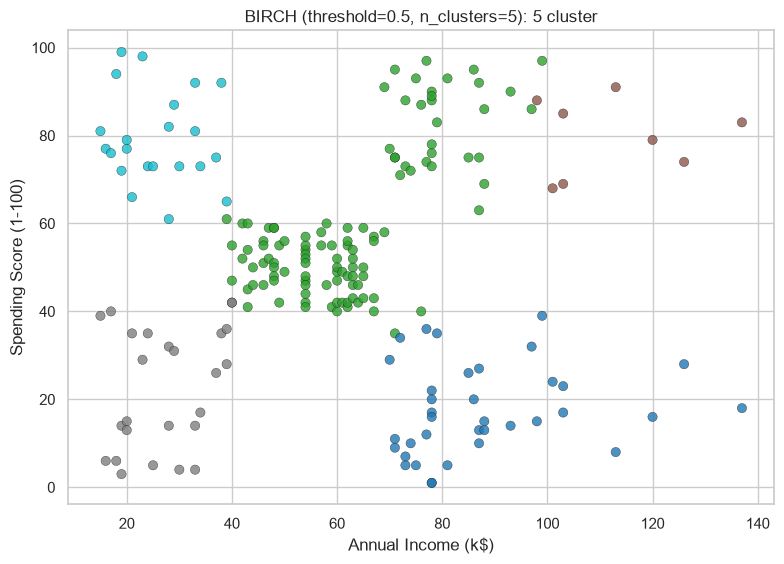

In [14]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.

xi, yi = X[feats[0]].values, X[feats[1]].values

plt.figure(figsize=(8, 5.8))
plt.scatter(xi, yi, c=labels_birch, cmap="tab10", s=45, alpha=0.8,
            edgecolor="k", linewidth=0.3)
plt.xlabel(feats[0])
plt.ylabel(feats[1])
plt.title(f"BIRCH (threshold=0.5, n_clusters=5): {len(set(labels_birch))} cluster")
plt.tight_layout()
plt.show()


In [15]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.

rows = []
for th in [0.3, 0.5, 0.7, 1.0]:
    lab = Birch(threshold=th, n_clusters=5).fit_predict(X_scaled)
    n_cl = len(set(lab))
    sil = round(silhouette_score(X_scaled, lab), 4) if 2 <= n_cl < len(lab) else None
    sizes = " / ".join(str(v) for v in sorted(np.bincount(lab), reverse=True))
    rows.append({"threshold": th, "n_clusters_param": 5, "jumlah_cluster": n_cl,
                 "silhouette": sil, "ukuran_cluster": sizes})
birch_cmp = pd.DataFrame(rows)
print(birch_cmp.to_string(index=False))

best_b = birch_cmp.loc[birch_cmp["silhouette"].idxmax()]
labels_birch_best = Birch(threshold=float(best_b["threshold"]), n_clusters=5).fit_predict(X_scaled)
print("\nBIRCH terbaik: threshold =", best_b["threshold"],
      "| silhouette =", best_b["silhouette"])

# Tanpa n_clusters: jumlah cluster akhir ditentukan oleh jumlah subcluster pohon
print("\nBIRCH tanpa parameter n_clusters:")
rows = []
for th in [0.3, 0.5, 0.7, 1.0]:
    lab = Birch(threshold=th, n_clusters=None).fit_predict(X_scaled)
    n_cl = len(set(lab))
    sil = round(silhouette_score(X_scaled, lab), 4) if 2 <= n_cl < len(lab) else None
    rows.append({"threshold": th, "jumlah_cluster": n_cl, "silhouette": sil})
print(pd.DataFrame(rows).to_string(index=False))


 threshold  n_clusters_param  jumlah_cluster  silhouette         ukuran_cluster
       0.3                 5               5      0.4781 101 / 38 / 36 / 22 / 3
       0.5                 5               5      0.4145 109 / 36 / 25 / 22 / 8
       0.7                 5               5      0.4207  96 / 35 / 33 / 32 / 4
       1.0                 5               4      0.3886     109 / 36 / 30 / 25

BIRCH terbaik: threshold = 0.3 | silhouette = 0.4781

BIRCH tanpa parameter n_clusters:
 threshold  jumlah_cluster  silhouette
       0.3              23      0.4143
       0.5              10      0.4774
       0.7               6      0.4861
       1.0               4      0.3886


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?
**Jawaban:**

- **Pengaruh `threshold`:** Threshold yang diperbesar membuat subcluster lebih besar, sehingga jumlah cluster akhir cenderung **mengecil** dan silhouette menurun. Dengan `n_clusters=5`: threshold 0.3 → silhouette 0.4781 (5 cluster), 0.5 → 0.4145, 0.7 → 0.4207, 1.0 → 0.3886 dan hanya **4 cluster** yang berhasil terbentuk (tidak sampai 5). Tanpa `n_clusters`, pengaruhnya makin jelas: 23 cluster (0.3) → 10 (0.5) → 6 (0.7) → 4 (1.0).
- **BIRCH vs DBSCAN:** DBSCAN menandai titik yang tidak cukup padat sebagai noise (`-1`) dan tidak memasukkannya ke cluster mana pun (55 titik pada hasil terbaik). BIRCH tidak memiliki label noise — titik yang jauh tetap dipaksa masuk ke subcluster terdekat, lalu ke cluster terdekat, sehingga semua titik selalu "terwakili" di suatu cluster.
- **Apakah hasil berubah ketika `n_clusters` ditentukan?** Ya. BIRCH menggabungkan centroid subcluster yang sudah terbentuk (agglomeratif pada *leaf*), jadi `n_clusters=5` memaksa 10 subcluster (threshold=0.5, tanpa `n_clusters`) menyusut menjadi 5 cluster — jumlahnya tepat, tetapi silhouette sedikit menurun (0.4774 → 0.4145). Selain itu, jika jumlah subcluster kurang dari `n_clusters`, cluster akhir bisa tidak mencapai yang diminta (threshold=1.0 → 4 cluster, bukan 5).


# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [16]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.

gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=RANDOM_STATE)
labels_gmm = gmm.fit_predict(X_scaled)

print("GaussianMixture(n_components=5, covariance_type='full', random_state=42) selesai.")
print("Label unik:", sorted(set(labels_gmm)))


GaussianMixture(n_components=5, covariance_type='full', random_state=42) selesai.
Label unik: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [17]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.

vc = pd.Series(labels_gmm).value_counts().sort_index()
print("Jumlah anggota setiap cluster GMM:")
print(vc.to_string())

proba = gmm.predict_proba(X_scaled)
print("\n5 baris pertama probabilitas keanggotaan (kolom = komponen 0-4):")
print(pd.DataFrame(np.round(proba, 3)).head().to_string())

maxp = proba.max(axis=1)
print(f"\nProbabilitas terbesar per titik: rata-rata={maxp.mean():.4f}, minimum={maxp.min():.4f}")
print("Titik dengan probabilitas < 0.7 (relatif tidak pasti):",
      int((maxp < 0.7).sum()), "dari", len(maxp))
print("Titik dengan probabilitas < 0.9:", int((maxp < 0.9).sum()), "dari", len(maxp))


Jumlah anggota setiap cluster GMM:
0    84
1    39
2    21
3    33
4    23

5 baris pertama probabilitas keanggotaan (kolom = komponen 0-4):
     0    1      2    3      4
0  0.0  0.0  0.001  0.0  0.999
1  0.0  0.0  1.000  0.0  0.000
2  0.0  0.0  0.000  0.0  1.000
3  0.0  0.0  1.000  0.0  0.000
4  0.0  0.0  0.002  0.0  0.998

Probabilitas terbesar per titik: rata-rata=0.9827, minimum=0.5029
Titik dengan probabilitas < 0.7 (relatif tidak pasti): 4 dari 200
Titik dengan probabilitas < 0.9: 8 dari 200


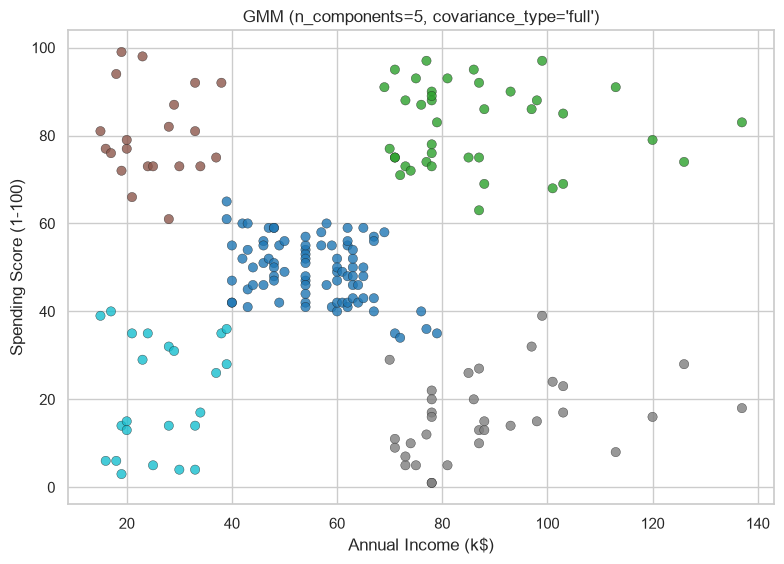

In [18]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.

xi, yi = X[feats[0]].values, X[feats[1]].values

plt.figure(figsize=(8, 5.8))
plt.scatter(xi, yi, c=labels_gmm, cmap="tab10", s=45, alpha=0.8,
            edgecolor="k", linewidth=0.3)
plt.xlabel(feats[0])
plt.ylabel(feats[1])
plt.title("GMM (n_components=5, covariance_type='full')")
plt.tight_layout()
plt.show()


In [19]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.

rows = []
for k in range(2, 9):
    g = GaussianMixture(n_components=k, covariance_type="full",
                        random_state=RANDOM_STATE).fit(X_scaled)
    lab = g.predict(X_scaled)
    rows.append({"n_components": k,
                 "silhouette": round(silhouette_score(X_scaled, lab), 4),
                 "BIC": round(g.bic(X_scaled), 1),
                 "AIC": round(g.aic(X_scaled), 1),
                 "iterasi": g.n_iter_})
gmm_cmp = pd.DataFrame(rows)
print(gmm_cmp.to_string(index=False))

k_sil = int(gmm_cmp.loc[gmm_cmp["silhouette"].idxmax(), "n_components"])
k_bic = int(gmm_cmp.loc[gmm_cmp["BIC"].idxmin(), "n_components"])
print("\nSilhouette tertinggi pada n_components =", k_sil)
print("BIC terendah pada n_components =", k_bic)


 n_components  silhouette    BIC    AIC  iterasi
            2      0.3791 1153.9 1117.6        6
            3      0.4302 1151.7 1095.6        8
            4      0.4134 1103.8 1027.9        8
            5      0.5537 1058.7  963.0        5
            6      0.5170 1074.7  959.2        5
            7      0.5091 1087.3  952.1        6
            8      0.4302 1102.4  947.3        8

Silhouette tertinggi pada n_components = 5
BIC terendah pada n_components = 5


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?
**Jawaban:**

- **Probabilitas keanggotaan:** `predict_proba` menghasilkan posterior P(komponen | titik) — seberapa yakin titik berasal dari tiap Gaussian, dan label cluster diambil dari komponen dengan probabilitas terbesar. Probabilitas maksimum yang rendah menandakan titik yang berada di batas antar komponen. Pada GMM k=5, rata-rata probabilitas maksimum 0.9827, minimum 0.5029, dan hanya 4 titik yang di bawah 0.7 — hampir semua titik yakin terhadap satu komponen.
- **Ketika `n_components` diubah (2–8):** Silhouette naik dari 0.3791 (k=2) hingga maksimum 0.5537 di k=5, lalu menurun lagi (k=8: 0.4302). BIC juga paling rendah di k=5 (1058,7) lalu naik (k=6: 1074,7; k=7: 1087,3; k=8: 1102,4), sedangkan AIC justru terus menurun karena AIC tidak sepenuhnya menghukum penambahan parameter.
- **Mengapa harus ditentukan di awal:** GMM adalah model parametrik; EM hanya mengestimasi parameter (μ, Σ, dan π) dari sejumlah komponen yang sudah ditetapkan. EM tidak menemukan jumlah komponen sendiri.
- **Silhouette tertinggi vs BIC terendah:** **Sama-sama berada di k=5**, sehingga k=5 adalah pilihan yang konsisten menurut kedua kriteria.


# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [20]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.

def evaluate(X, labels, name=""):
    """Metrik internal clustering; label noise (-1) dikeluarkan (umumnya DBSCAN)."""
    labels = np.asarray(labels)
    mask = labels != -1
    Xv = np.asarray(X)[mask]
    L = labels[mask]
    n_cl = len(set(L))
    n_noise = int((labels == -1).sum())
    # metrik hanya valid jika >= 2 cluster dan jumlah cluster < jumlah titik
    if n_cl < 2 or n_cl >= len(L):
        return {"model": name, "n_clusters": n_cl, "noise": n_noise,
                "silhouette": None, "davies_bouldin": None, "calinski_harabasz": None}
    return {"model": name, "n_clusters": n_cl, "noise": n_noise,
            "silhouette": round(silhouette_score(Xv, L), 4),
            "davies_bouldin": round(davies_bouldin_score(Xv, L), 4),
            "calinski_harabasz": round(calinski_harabasz_score(Xv, L), 2)}


In [21]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.

hasil = [
    evaluate(X_scaled, labels_dbscan_best,
             f"DBSCAN (eps={float(best['eps']):g}, min_samples={int(best['min_samples'])})"),
    evaluate(X_scaled, labels_birch_best,
             f"BIRCH (threshold={float(best_b['threshold']):g}, n_clusters=5)"),
    evaluate(X_scaled, labels_gmm, "GMM/EM (n_components=5, full)"),
]
eval_df = pd.DataFrame(hasil)
print(eval_df.to_string(index=False))


                              model  n_clusters  noise  silhouette  davies_bouldin  calinski_harabasz
   DBSCAN (eps=0.35, min_samples=8)           4     55      0.5994          0.4713             252.79
BIRCH (threshold=0.3, n_clusters=5)           5      0      0.4781          0.6477             144.01
      GMM/EM (n_components=5, full)           5      0      0.5537          0.5760             244.94


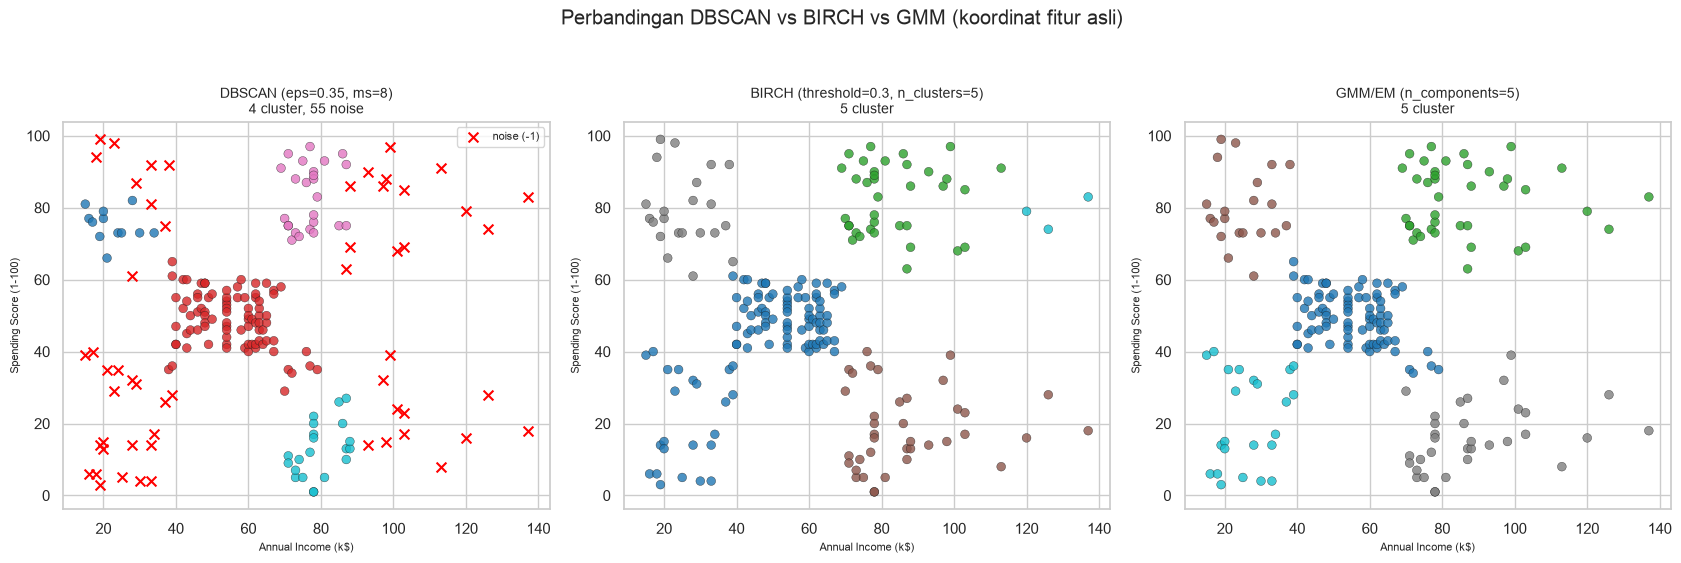

In [22]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.

n_cl_db = len(set(labels_dbscan_best) - {-1})
noise_db = int((labels_dbscan_best == -1).sum())
n_cl_b = len(set(labels_birch_best))
n_cl_g = len(set(labels_gmm))

panels = [
    (labels_dbscan_best,
     f"DBSCAN (eps={float(best['eps']):g}, ms={int(best['min_samples'])})\n"
     f"{n_cl_db} cluster, {noise_db} noise"),
    (labels_birch_best,
     f"BIRCH (threshold={float(best_b['threshold']):g}, n_clusters=5)\n{n_cl_b} cluster"),
    (labels_gmm, f"GMM/EM (n_components=5)\n{n_cl_g} cluster"),
]
xi, yi = X[feats[0]].values, X[feats[1]].values

fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
for ax, (lab, judul) in zip(axes, panels):
    m = lab != -1
    if m.any():
        ax.scatter(xi[m], yi[m], c=lab[m], cmap="tab10", s=40, alpha=0.8,
                   edgecolor="k", linewidth=0.3)
    if (~m).any():
        ax.scatter(xi[~m], yi[~m], c="red", marker="x", s=50, label="noise (-1)")
        ax.legend(fontsize=8)
    ax.set_title(judul, fontsize=10)
    ax.set_xlabel(feats[0], fontsize=8)
    ax.set_ylabel(feats[1], fontsize=8)
plt.suptitle("Perbandingan DBSCAN vs BIRCH vs GMM (koordinat fitur asli)", y=1.04)
plt.tight_layout()
plt.show()


In [23]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.

def tampilkan_profil(nama, lab):
    t = X.copy()
    t["cluster"] = np.asarray(lab)
    g = t.groupby("cluster")
    prof = pd.DataFrame({
        "jumlah": g.size(),
        "median_income": g[feats[0]].median(),
        "median_spending": g[feats[1]].median(),
        "mean_income": g[feats[0]].mean().round(1),
        "mean_spending": g[feats[1]].mean().round(1),
    })
    print(f"\n=== {nama} ===")
    print(prof.round(1).to_string())
    if (np.asarray(lab) == -1).any():
        print("(label -1 = titik noise, dibaca terpisah dari cluster)")

tampilkan_profil(f"DBSCAN (eps={float(best['eps']):g}, min_samples={int(best['min_samples'])})",
                 labels_dbscan_best)
tampilkan_profil(f"BIRCH (threshold={float(best_b['threshold']):g}, n_clusters=5)",
                 labels_birch_best)
tampilkan_profil("GMM/EM (n_components=5, full)", labels_gmm)



=== DBSCAN (eps=0.35, min_samples=8) ===
         jumlah  median_income  median_spending  mean_income  mean_spending
cluster                                                                    
-1           55           37.0             35.0         62.3           46.4
 0           12           20.5             74.5         22.4           75.2
 1           87           54.0             49.0         55.4           48.8
 2           25           77.0             83.0         76.9           83.0
 3           21           78.0             12.0         79.6           12.6
(label -1 = titik noise, dibaca terpisah dari cluster)

=== BIRCH (threshold=0.3, n_clusters=5) ===
         jumlah  median_income  median_spending  mean_income  mean_spending
cluster                                                                    
0           101           50.0             47.0         48.2           43.4
1            36           78.0             85.5         83.1           82.4
2            38       

### Ringkasan Perbandingan

Tabel berikut disusun dari hasil eksperimen di atas (DBSCAN terbaik eps=0.35/min_samples=8; BIRCH terbaik threshold=0.3/n_clusters=5; GMM n_components=5).

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak — jumlah cluster muncul dari kepadatan (4 cluster + 55 noise pada hasil terbaik) | Tidak wajib; jika `n_clusters` diisi, jumlah akhir dipaksa sesuai (5 cluster) | Ya — `n_components` harus ditentukan di awal (5) |
| Dapat memberi label noise secara eksplisit? | Ya, label `-1` (55 titik) | Tidak (semua titik selalu masuk suatu cluster) | Tidak (semua titik punya keanggotaan, meski bisa tidak pasti) |
| Parameter yang paling memengaruhi hasil | `eps` dan `min_samples` | `threshold` dan `n_clusters` | `n_components` dan `covariance_type` |
| Bentuk cluster yang dapat dimodelkan | Bebas bentuk mengikuti kepadatan, termasuk non-convex | Kira-kira bulat, sesuai radius `threshold` subcluster | Elips sesuai matriks kovarians (`full` = elips bebas) |
| Kelebihan | Tidak perlu k; otomatis mengenali outlier/noise | Cepat dan ringkas (struktur pohon); mudah diskalakan | Probabilitas keanggotaan; model probabilistik yang rigor |
| Kekurangan | Sangat sensitif terhadap `eps`/`min_samples`; sulit untuk kepadatan tidak seragam | Rentan pengaruh `threshold`; cluster bisa sangat tidak seimbang (ada cluster berisi 3 anggota) | Harus menebak jumlah `k`; mengasumsikan data berdistribusi Gaussian |

**Ringkasan metrik (semakin tinggi silhouette/Calinski-Harabasz, semakin rendah Davies-Bouldin, semakin baik):**

| Model (hasil terbaik) | Cluster | Noise | Silhouette | Davies-Bouldin | Calinski-Harabasz |
|---|---|---|---|---|---|
| DBSCAN (eps=0.35, ms=8) | 4 | 55 | 0.5994 | 0.4713 | 252.79 |
| BIRCH (threshold=0.3, nc=5) | 5 | 0 | 0.4781 | 0.6477 | 144.01 |
| GMM/EM (n_components=5) | 5 | 0 | 0.5537 | 0.5760 | 244.94 |

DBSCAN unggul di ketiga metrik, tetapi hanya menilai 145 titik non-noise; GMM mendekati DBSCAN sambil tetap melabeli seluruh 200 pelanggan; BIRCH paling lemah pada metrik ini.


# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?
**Jawaban:**

1. **Mengapa fitur perlu di-scaling?** DBSCAN menentukan tetangga dari jarak Euclidean terhadap `eps`, BIRCH mengelompokkan titik dalam radius `threshold`, dan GMM memodelkan sebaran tiap dimensi — ketiganya bergantung pada skala fitur. Sebelum scaling, rentang `Annual Income` (15–137) lebih lebar daripada `Spending Score` (1–99), sehingga jarak hampir hanya ditentukan oleh pendapatan. Setelah `StandardScaler`, tiap kolom bermean 0 dan berstd 1 sehingga kedua sumbu sebanding (lihat cell "scatter sebelum dan sesudah scaling").

2. **Pengaruh parameter DBSCAN.** `eps` naik → cluster saling menyatu dan noise terserap (pada min_samples=5: 7 cluster/77 noise di eps=0.2 menjadi 4/15 di eps=0.4, lalu 1 cluster/5 noise di eps=0.6). `min_samples` naik → syarat *core point* makin ketat → cluster berkurang dan noise bertambah (pada eps=0.3: 9 cluster/14 noise di min_samples=3 menjadi 4/88 di min_samples=10). Kombinasi ekstrem menghasilkan satu cluster raksasa (eps=0.6, ms=3) atau noise yang mendominasi (eps=0.2, ms=10 → 129 noise). Kombinasi terbaik menurut aturan pemilihan: **eps=0.35, min_samples=8** (4 cluster, 55 noise, silhouette 0.5994).

3. **Pengaruh `threshold` dan `n_clusters` pada BIRCH.** `threshold` besar → subcluster besar → jumlah cluster mengecil dan silhouette turun (dengan `n_clusters=5`: 0.4781 → 0.4145 → 0.4207 → 0.3886; tanpa `n_clusters`: 23 → 10 → 6 → 4 cluster). `n_clusters` menggabungkan centroid subcluster agar jumlah akhir tepat 5, tetapi jumlahnya dibatasi jumlah subcluster yang terbentuk (threshold=1.0 hanya menghasilkan 4 cluster meski diminta 5).

4. **Probabilitas keanggotaan GMM dan peran EM.** Pada E-step, EM menghitung posterior P(komponen | titik) untuk setiap titik; pada M-step, parameter μ, Σ, dan π diperbarui dari probabilitas itu, lalu diulang hingga konvergen. Label cluster diambil dari komponen dengan probabilitas terbesar. Probabilitas maksimum yang tinggi berarti titik yakin berada di satu komponen (rata-rata 0.9827; hanya 4 titik < 0.7), sedangkan nilai yang rendah menandakan titik batas antar komponen.

5. **Model paling mudah diinterpretasikan: GMM.** Semua 200 pelanggan terlabeli tanpa noise, jumlah cluster jelas (5, konsisten dari silhouette dan BIC), profil per cluster mudah dibaca, dan tiap titik punya skor keyakinan. BIRCH juga sederhana, tetapi hasilnya tidak seimbang (cluster berisi 101 vs 3 anggota) dan tanpa probabilitas. DBSCAN paling sulit: 55 titik (27,5%) tidak masuk cluster mana pun, dan hasilnya sangat berubah hanya dengan menggeser `eps` sedikit.

6. **Apakah metrik menunjukkan algoritma terbaik yang sama?** Ya, pada kasus ini ketiga metrik sepakat: DBSCAN terbaik (silhouette 0.5994, DB 0.4713, CH 252.79), disusul GMM (0.5537 / 0.5760 / 244.94), lalu BIRCH (0.4781 / 0.6477 / 144.01). Namun perlu dicatat penyebab perbedaan tingkatannya: metrik DBSCAN dihitung hanya pada 145 titik non-noise (noise dibuang sehingga cluster yang tersisa tampak lebih padat), sementara GMM dan BIRCH dinilai pada seluruh 200 titik termasuk titik-titik sulit. Jadi unggulnya DBSCAN sebagian berasal dari "membuang" kasus yang paling sulit, bukan berarti hasilnya otomatis paling berguna.

7. **Karakteristik cluster dan nama deskriptif** (berdasarkan median/rata-rata pada profil GMM k=5):

   | Cluster | Jumlah | Median income | Median spending | Nama deskriptif |
   |---|---|---|---|---|
   | 0 | 84 | 55,5 | 49,5 | **Menengah Rata-rata** — penghasilan dan belanja di tengah |
   | 1 | 39 | 79,0 | 83,0 | **Big Spender** — pendapatan tinggi, belanja tinggi |
   | 2 | 21 | 24,0 | 77,0 | **Target Pasar Boros** — pendapatan rendah tetapi belanja tinggi |
   | 3 | 33 | 86,0 | 15,0 | **Pembeli Hemat Kaya** — pendapatan tinggi, belanja rendah |
   | 4 | 23 | 25,0 | 17,0 | **Penghemat Konservatif** — pendapatan dan belanja sama-sama rendah |

   Pada DBSCAN terbaik, 4 cluster yang terbentuk mengulang tiga gugusan sudut (0: pendapatan rendah/belanja tinggi, 2: tinggi/tinggi, 3: tinggi/rendah) plus satu cluster tengah yang besar (87 titik); sedangkan gugusan "pendapatan rendah/belanja rendah" justru sebagian besar jadi noise (55 titik, median pendapatan 37, median spending 35) karena kepadatannya tidak cukup. BIRCH terbaik memberi hasil mirip GMM, tetapi memecah 3 pelanggan berpendapatan sangat tinggi (median 126) menjadi cluster tersendiri.

8. **Keterbatasan dua fitur dan dataset kecil.** (a) Dua fitur hanya merepresentasikan sisi pendapatan dan belanja — segmentasi bisa berubah bila umur/gender ditambahkan; (b) bentuk cluster pada ruang 2D tidak tentu bertahan di ruang fitur yang lebih tinggi; (c) 200 baris sangat kecil sehingga hasil sensitif terhadap sedikit outlier dan perubahan parameter — GMM k=5 dengan `covariance_type='full'` menaksir ±30 parameter dari hanya 400 angka data, berisiko overfit; (d) tanpa data waktu atau riwayat transaksi, klasterisasi ini hanya "potret sesaat" dan tidak menunjukkan perilaku jangka panjang pelanggan.


# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.
**Kesimpulan berdasarkan hasil eksperimen:**

- **Algoritma paling berguna untuk dataset ini: GMM (EM).** Seluruh 200 pelanggan terbagi ke 5 segmen yang jelas dan mudah diinterpretasikan (Menengah Rata-rata, Big Spender, Target Pasar Boros, Pembeli Hemat Kaya, Penghemat Konservatif), kualitas metrik hampir menyamai DBSCAN terbaik (silhouette 0.5537 vs 0.5994), tanpa ada titik yang dibuang sebagai noise, plus tersedia probabilitas keanggotaan (rata-rata 0.9827). K=5 juga konsisten dari dua kriteria: silhouette tertinggi dan BIC terendah.
- **Parameter yang dipilih dan alasannya:** DBSCAN → **eps=0.35, min_samples=8** (silhouette tertinggi di antara kombinasi dengan ≥3 cluster dan noise ≤30% dari data: 0.5994, 4 cluster, 55 noise). BIRCH → **threshold=0.3, n_clusters=5** (silhouette tertinggi di antara threshold yang dicoba: 0.4781). GMM → **n_components=5, covariance_type='full', random_state=42** (silhouette tertinggi sekaligus BIC terendah pada rentang k=2–8).
- **Perbedaan utama yang dipelajari:** DBSCAN berbasis kepadatan, tidak perlu jumlah cluster di awal, dan satu-satunya yang menandai noise secara eksplisit — tetapi paling sensitif terhadap `eps`/`min_samples` dan hanya unggul karena 55 titik sulitnya dikeluarkan dari perhitungan metrik. BIRCH merangkum data ke pohon subcluster sehingga cepat dan sederhana, tetapi tanpa label noise dan sangat bergantung pada `threshold` (jumlah cluster akhir bisa tidak mencapai `n_clusters` yang diminta). GMM probabilistik: jumlah komponen harus ditentukan di awal, asumsinya Gaussian, tetapi hasilnya paling stabil, lengkap dengan skor keyakinan tiap titik.
- **Eksperimen lanjutan:** (1) menambah fitur (misalnya `Age` dan `Gender` dengan encoding) untuk melihat apakah segmen bertahan; (2) mencoba DBSCAN dengan metrik jarak lain atau HDBSCAN untuk kepadatan tidak seragam; (3) tuning parameter BIRCH (`branching_factor`) dan `covariance_type` GMM; (4) validasi hasil dengan sampel data lebih besar (bootstrap) serta uji interpretasi bersama pihak domain (marketing); (5) membandingkan dengan K-Means pada jumlah cluster yang sama.
